In [1]:
#Imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [2]:
#Load Data
data = pd.read_csv('/content/heart.csv')

In [3]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
data.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [36]:
#Assign Values
x = data.drop('target', axis=1)
y = data['target']

In [37]:
from sklearn.preprocessing import MinMaxScaler

Scaler = MinMaxScaler()
x = Scaler.fit_transform(x)
x

array([[0.70833333, 1.        , 1.        , ..., 0.        , 0.        ,
        0.33333333],
       [0.16666667, 1.        , 0.66666667, ..., 0.        , 0.        ,
        0.66666667],
       [0.25      , 0.        , 0.33333333, ..., 1.        , 0.        ,
        0.66666667],
       ...,
       [0.8125    , 1.        , 0.        , ..., 0.5       , 0.5       ,
        1.        ],
       [0.58333333, 1.        , 0.        , ..., 0.5       , 0.25      ,
        1.        ],
       [0.58333333, 0.        , 0.33333333, ..., 0.5       , 0.25      ,
        0.66666667]])

In [54]:
#Split and train
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [55]:
#Train Model
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [56]:
#predict values
predict_out = model.predict(x_test)
print(predict_out)

[0 0 0 1 1 0 1 0 1 1 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 0 1 0 0 0 1 1
 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1]


In [57]:
#Comparison
comparison = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : predict_out
})

print(comparison)

     Actual  Predicted
179       0          0
197       0          0
285       0          0
194       0          1
188       0          1
..      ...        ...
14        1          1
4         1          1
224       0          0
202       0          0
12        1          1

[61 rows x 2 columns]


In [58]:
#Evaluation

#Accuracy Score

Accuracy = accuracy_score(y_test, predict_out)
print(Accuracy)

0.7868852459016393


In [59]:
#Confusion Matrix
cm = confusion_matrix(y_test, predict_out)
print(cm)

[[18 10]
 [ 3 30]]


In [60]:
#Classification Report
cr = classification_report(y_test, predict_out)
print(cr)

              precision    recall  f1-score   support

           0       0.86      0.64      0.73        28
           1       0.75      0.91      0.82        33

    accuracy                           0.79        61
   macro avg       0.80      0.78      0.78        61
weighted avg       0.80      0.79      0.78        61



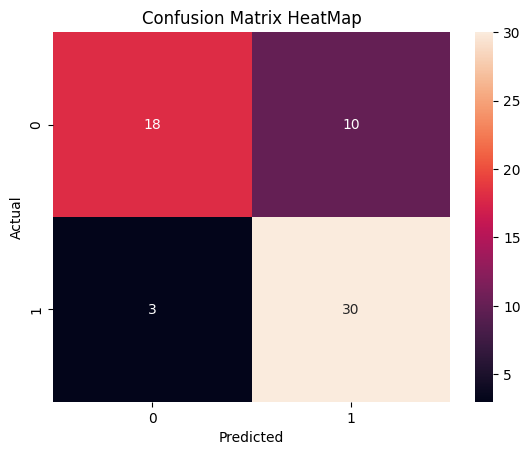

In [46]:
#Visualization
sns.heatmap(cm, annot=True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix HeatMap' )
plt.show()

In [140]:
#Future Prediction

sample = data.sample(1)
sample

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
217,63,1,0,130,330,1,0,132,1,1.8,2,3,3,0


In [142]:
sample = sample.drop('target', axis=1)
sample

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
217,63,1,0,130,330,1,0,132,1,1.8,2,3,3


In [143]:
predict = model.predict(sample)
predict

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


array([0])